# Homework 4A. Conditional models: Gaussian and logistic regression
**Machine Learning: Mathematical Basis** (D.B. Rokhlin, 2026)

**Student:** Goriola-Obafemi Babatunde Sukanmi

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, accuracy_score

## Task 1. Same prediction, different log-loss

Model A: $Y\mid X=x \sim \mathcal N(1+x,\ 0.25)$, Model B: $Y\mid X=x \sim \mathcal N(1+x,\ 1)$.

For $Y\sim\mathcal N(m,v)$:
$$-\log p(y)=\tfrac12\log(2\pi v)+\frac{(y-m)^2}{2v}.$$

Both models have mean $m(x)=1+x$, so the means at $x=0,1,2$ are $1,2,3$ and the residuals are $y_i-m(x_i)=0,\ 0,\ 1.5$.

In [2]:
x = np.array([0., 1., 2.])
y = np.array([1., 2., 4.5])
m = 1 + x
models = {"A": 0.25, "B": 1.0}

def nll(y, m, v):
    return 0.5*np.log(2*np.pi*v) + (y - m)**2/(2*v)

for name, v in models.items():
    terms = nll(y, m, v)
    print(f"Model {name} (v={v}): per-point NLL = {np.round(terms, 4)}")
    print(f"   average log-loss, 3 points = {terms.mean():.4f}")
    print(f"   average log-loss, first 2  = {terms[:2].mean():.4f}")

Model A (v=0.25): per-point NLL = [0.2258 0.2258 4.7258]
   average log-loss, 3 points = 1.7258
   average log-loss, first 2  = 0.2258
Model B (v=1.0): per-point NLL = [0.9189 0.9189 2.0439]
   average log-loss, 3 points = 1.2939
   average log-loss, first 2  = 0.9189


### a. Average log-loss on all three points

**Model A** ($v=0.25$): $\tfrac12\log(2\pi\cdot 0.25)=\tfrac12\log(\pi/2)\approx 0.2258$.
$$L_A=\frac13\Big[3(0.2258)+\frac{1.5^2}{2\cdot 0.25}\Big]=\frac13\big[0.6774+4.5\big]\approx 1.7258.$$

**Model B** ($v=1$): $\tfrac12\log(2\pi)\approx 0.9189$.
$$L_B=\frac13\Big[3(0.9189)+\frac{1.5^2}{2}\Big]=\frac13\big[2.7568+1.125\big]\approx 1.2939.$$

$L_B<L_A$, so **Model B is better** on the full validation set.

### b. Only the first two observations

Both residuals are $0$, so only the normalising term remains:
$$L_A=\tfrac12\log(2\pi\cdot0.25)\approx 0.2258,\qquad L_B=\tfrac12\log(2\pi)\approx 0.9189.$$

Now **Model A is better**. When the data lie exactly on the mean, a narrower (more confident) density puts more mass there, so its log-loss is smaller. The third point has residual $1.5$, which is $3$ standard deviations for A ($\sigma_A=0.5$) but only $1.5$ for B ($\sigma_B=1$). The penalty $\frac{(y-m)^2}{2v}$ is $4.5$ for A versus $1.125$ for B, so one surprising observation reverses the ranking. Log-loss rewards confidence when it is justified and punishes overconfidence heavily.

### c. Point prediction at $x=3$

Under squared loss the optimal prediction is the conditional mean $\mathbb E[Y\mid X=3]=1+3=4$ for **both** models.

The log-loss values differ because log-loss evaluates the whole predictive distribution, not just its centre. Both models share the mean but have different variances ($0.25$ vs $1$), i.e. different stated uncertainty. Squared error depends only on the mean, so it cannot distinguish them; log-loss depends on $v$ through both $\tfrac12\log(2\pi v)$ and $\frac{(y-m)^2}{2v}$, so it rewards the model whose uncertainty matches how spread out the data actually are.

## Task 2. Logistic regression with nonlinear features

Model 1: $p(1\mid x)=\sigma(a+bx)$. Model 2: $p(1\mid x)=\sigma(a+bx+cx^2)$, with $\sigma(t)=\frac{1}{1+e^{-t}}$.

### a. Fitting

In [3]:
x_tr = np.array([-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2])
y_tr = np.array([ 1,  1,    0,  0,   0, 0,   0, 1,   1])
x_va = np.array([-1.75, -0.75, 0.75, 1.75])
y_va = np.array([ 1,     0,    0,    1])

def feat1(x): return x.reshape(-1, 1)
def feat2(x): return np.column_stack([x, x**2])

m1 = LogisticRegression(C=1, max_iter=1000).fit(feat1(x_tr), y_tr)
m2 = LogisticRegression(C=1, max_iter=1000).fit(feat2(x_tr), y_tr)

print(f"Model 1: a = {m1.intercept_[0]: .4f}, b = {m1.coef_[0,0]: .4f}")
print(f"Model 2: a = {m2.intercept_[0]: .4f}, b = {m2.coef_[0,0]: .4f}, c = {m2.coef_[0,1]: .4f}")

Model 1: a = -0.2231, b =  0.0000
Model 2: a = -2.4806, b =  0.0000, c =  1.3805


### b. Validation log-loss and accuracy

Validation log-loss: $-\frac1n\sum_i\big[y_i\log\hat p_i+(1-y_i)\log(1-\hat p_i)\big]$; accuracy uses the threshold $\hat p_i\ge 0.5$.

In [4]:
import pandas as pd

p1 = m1.predict_proba(feat1(x_va))[:, 1]
p2 = m2.predict_proba(feat2(x_va))[:, 1]

print(pd.DataFrame({"x": x_va, "y": y_va,
                    "p1(1|x)": p1.round(4), "pred1": (p1 >= 0.5).astype(int),
                    "p2(1|x)": p2.round(4), "pred2": (p2 >= 0.5).astype(int)}).to_string(index=False))

res = pd.DataFrame({
    "log-loss": [log_loss(y_va, p1, labels=[0, 1]), log_loss(y_va, p2, labels=[0, 1])],
    "accuracy": [accuracy_score(y_va, (p1 >= 0.5).astype(int)),
                 accuracy_score(y_va, (p2 >= 0.5).astype(int))]},
    index=["Model 1 (linear)", "Model 2 (quadratic)"])
print()
print(res.round(4))

    x  y  p1(1|x)  pred1  p2(1|x)  pred2
-1.75  1   0.4445      0   0.8516      1
-0.75  0   0.4445      0   0.1539      0
 0.75  0   0.4445      0   0.1539      0
 1.75  1   0.4445      0   0.8516      1



                     log-loss  accuracy
Model 1 (linear)       0.6994       0.5
Model 2 (quadratic)    0.1639       1.0


**Model 2 is better**: it has a much lower validation log-loss and higher accuracy. Model 1 gives probabilities near $0.5$ everywhere, so it is essentially guessing (log-loss close to $\log 2\approx0.693$), while Model 2 assigns high probability to the correct class at all four validation points.

### c. Plot of the fitted $p(1\mid x)$ on $[-2.5, 2.5]$

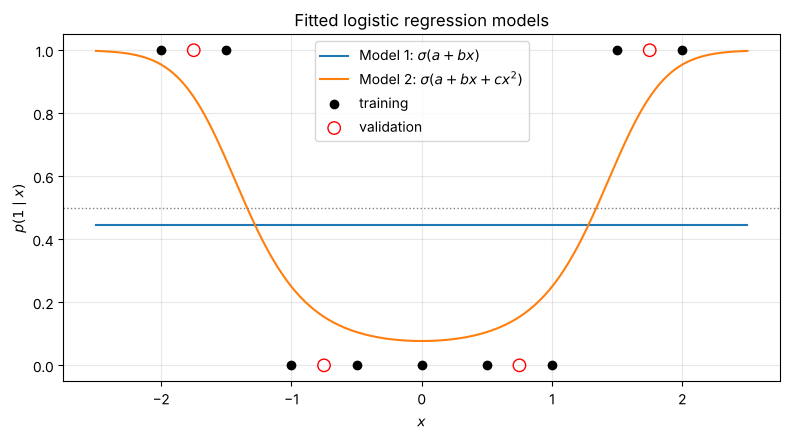

In [5]:
grid = np.linspace(-2.5, 2.5, 400)
plt.figure(figsize=(8, 4.5))
plt.plot(grid, m1.predict_proba(feat1(grid))[:, 1], label=r"Model 1: $\sigma(a+bx)$")
plt.plot(grid, m2.predict_proba(feat2(grid))[:, 1], label=r"Model 2: $\sigma(a+bx+cx^2)$")
plt.scatter(x_tr, y_tr, c="k", marker="o", zorder=3, label="training")
plt.scatter(x_va, y_va, facecolors="none", edgecolors="r", s=80, zorder=3, label="validation")
plt.axhline(0.5, color="gray", ls=":", lw=1)
plt.xlabel("$x$"); plt.ylabel(r"$p(1\mid x)$")
plt.title("Fitted logistic regression models")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Why the models behave differently.** The classes are arranged symmetrically: $y=1$ at both ends ($|x|\ge1.5$) and $y=0$ in the middle. Model 1 has a linear logit $a+bx$, so $p(1\mid x)$ is monotone in $x$ and its decision boundary is a single point; it cannot be high on both sides at once. Because the data are symmetric, the best it can do is $b\approx0$, giving an almost flat curve near the overall class frequency ($4/9$), which is why it predicts class 0 everywhere.

Model 2 has a quadratic logit $a+bx+cx^2$ with $c>0$ and $b\approx0$, so the logit is a U shape in $x$. The probability is low near $0$ and rises at both ends, giving two decision boundaries at $x\approx\pm\sqrt{-a/c}$. The feature $x^2$ makes the problem linearly separable in the feature space $(x,x^2)$. The curve is not a sharp step because $C=1$ adds $L_2$ regularisation, which keeps the coefficients moderate.